# 05 — Model Optimization

**Project:** Learning the Path of the Storm — 24-hour tropical cyclone track forecasting
**Author:** Yatharth Vardan · AAI-590 Capstone, University of San Diego

**Rubric section:** Model Optimization

In notebook 04, both recurrent networks beat XGBoost out of the box: 145.2 km for the GRU ensemble against
148.5 km. But they were trained with default settings and only 24 hours of history, which leaves some open
questions. So here we tune them, one question at a time:

1. **Loss function.** Is the gain over XGBoost really from reading the track as a sequence, or partly from
   training on distance error instead of squared error?
2. **History length.** Does the network forecast better if it sees 2 or 3 days of track instead of 1?
3. **Model size.** How many hidden units and recurrent layers does the problem need?

Rather than a large grid search, we change **one thing at a time**, keep whatever wins, and move on (a
"coordinate" search). That's far cheaper and much easier to interpret, which suits a laptop. The trade-off
is that it could miss a combination that only works when two settings change together, which we note in the
summary.

As always, every decision is made on the validation seasons (2017–2019), and the test seasons stay locked.

| | |
|---|---|
| **Input** | `data/processed/tracks_clean.csv.gz`; earlier validation errors from `preds_val_baselines.csv` and `preds_val_rnn.csv` |
| **Output** | `data/processed/preds_val_tuned.csv`, `models/tuned_*.pt`, `models/tuned_config.json`, figures `fig18`–`fig19` |

### Setting things up

Here we load the same tools as notebook 04: the sample and sequence builders, the network, and the training
loop, which now also accepts `loss="mse"` for the first experiment. XGBoost is deliberately *not* imported,
since it can't share a Python session with PyTorch on macOS (see notebook 04). Its validation errors come
from the file notebook 03 saved.

In [1]:
# Imports and paths
import sys
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

from stormtrack.data_io import load_clean, PROCESSED
from stormtrack.windows import (build_samples, build_sequences, persistence_displacement, track_error_km,
                                TARGET_COLS, STEP_FEATURES, STATIC_COLS)
from stormtrack.rnn import RNNForecaster, train_model, predict

FIG_DIR, MODEL_DIR = ROOT / "reports" / "figures", ROOT / "models"
torch.set_num_threads(4)
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
SEARCH_SEED, FINAL_SEEDS = 42, [42, 7, 2024]
print(f"PyTorch {torch.__version__} | training on: {DEVICE}")

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})

def savefig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/figures/{name}")

PyTorch 2.15.0 | training on: mps


## 1. Preparing data for different history lengths

To start, we rebuild the same 76,613 forecast samples and their static features as in notebook 04.

Since one experiment varies the history length, the cell below builds three versions of the sequences: 3
steps (24 hours, as before), 7 steps (48 hours) and 11 steps (72 hours). With longer histories, some
origins sit close to the start of their segment, so the oldest steps don't exist. Those steps are filled
with zeros and marked `valid = 0`. That way, every version forecasts exactly the same origins and the
errors stay directly comparable.

In [2]:
tracks = load_clean()
S = build_samples(tracks)
BASINS = sorted(S["BASIN"].unique())
for b in BASINS:
    S[f"basin_{b}"] = (S["BASIN"] == b).astype(float)
STATIC = STATIC_COLS + [f"basin_{b}" for b in BASINS]

HISTORIES = {3: "24 h", 7: "48 h", 11: "72 h"}
SEQS = {n: build_sequences(tracks, S, n_steps=n) for n in HISTORIES}
for n, arr in SEQS.items():
    print(f"{n:2d} steps ({HISTORIES[n]}): array {arr.shape}, "
          f"share of samples with full history: {(arr[:, 0, -1] == 1).mean():.0%}")

 3 steps (24 h): array (76613, 3, 5), share of samples with full history: 100%
 7 steps (48 h): array (76613, 7, 5), share of samples with full history: 79%
11 steps (72 h): array (76613, 11, 5), share of samples with full history: 62%


Next comes scaling, done as in notebook 04 with the mean and standard deviation from the training seasons
only, plus one refinement. With padded histories, the statistics are computed from **real steps only**, so
the zero padding doesn't drag the averages down. After scaling, padded steps are set back to exactly zero.
With 3 steps nothing is padded, so this reproduces notebook 04's scaling exactly.

In [3]:
is_tr, is_va = S["split"].eq("train").to_numpy(), S["split"].eq("val").to_numpy()
P = persistence_displacement(S)
Y = S[TARGET_COLS].to_numpy() - P                         # correction to persistence, km
y_scale = Y[is_tr].std(0)
ST = S[STATIC].to_numpy()
st_mu, st_sd = ST[is_tr].mean(0), ST[is_tr].std(0)
st_sd[st_sd == 0] = 1.0
va = S[is_va].reset_index(drop=True)
P_va = P[is_va]

def make_tensors(n_steps):
    seq = SEQS[n_steps]
    real = seq[is_tr][..., -1] == 1                       # real (not padded) training steps
    mu, sd = seq[is_tr][real].mean(0), seq[is_tr][real].std(0)
    mu[-1], sd[-1] = 0.0, 1.0                             # keep the 0/1 'valid' flag as is
    scaled = np.where(seq[..., -1:] == 1, (seq - mu) / sd, 0.0).astype(np.float32)
    t = lambda m: (torch.tensor(scaled[m]), torch.tensor((ST[m] - st_mu) / st_sd, dtype=torch.float32),
                   torch.tensor(Y[m] / y_scale, dtype=torch.float32))
    return t(is_tr), t(is_va), {"seq_mu": mu.tolist(), "seq_sd": sd.tolist()}

TENSORS = {n: make_tensors(n) for n in HISTORIES}
print("Tensors ready for", [f"{n} steps" for n in TENSORS])

Tensors ready for ['3 steps', '7 steps', '11 steps']


## 2. One helper to run every experiment

So that every experiment is run and recorded the same way, the helper below trains one network for a given
configuration, scores it on the validation seasons with the great-circle `track_error_km()`, and adds a row
to a running results log.

During the search, each configuration is trained **once**, with seed 42. That's a reasonable shortcut
because notebook 04 showed that results barely move between seeds: the three GRU runs spanned only 0.3 km.
To stay on the safe side, we treat any two configurations within **0.3 km** of each other as a tie, and
when there's a tie, we keep the simpler or cheaper option.

In [4]:
TIE_KM = 0.3
log = []

def run(experiment, cell="gru", n_steps=3, hidden=64, layers=1, loss="distance", dropout=0.1,
        seed=SEARCH_SEED, keep=False):
    train_t, val_t, _ = TENSORS[n_steps]
    torch.manual_seed(seed)
    model = RNNForecaster(len(STEP_FEATURES), len(STATIC), cell=cell, hidden=hidden, layers=layers, dropout=dropout)
    t0 = time.time()
    model, hist = train_model(model, train_t, val_t, y_scale, DEVICE, seed=seed, loss=loss, verbose=False)
    disp = predict(model, val_t[0], val_t[1], DEVICE) * y_scale + P_va
    err = track_error_km(va, disp)
    row = {"experiment": experiment, "cell": cell.upper(), "history": HISTORIES[n_steps], "hidden": hidden,
           "layers": layers, "loss": loss, "seed": seed, "val_mean_km": err.mean(),
           "val_NA_km": err[va["BASIN"].eq("NA").to_numpy()].mean(),
           "epochs": len(hist), "params": sum(p.numel() for p in model.parameters()),
           "secs": round(time.time() - t0)}
    log.append(row)
    return (row, model, disp, err) if keep else row

def table(experiment):
    t = pd.DataFrame([r for r in log if r["experiment"] == experiment])
    return t.drop(columns=["experiment", "seed"]).round(1)

## 3. Experiment A: distance loss or squared error?

First, the open question from notebook 04. The networks were trained to minimize the distance between
forecast and actual position, while XGBoost minimized squared error. To find out how much the loss
function matters on its own, the next cell trains the *same* GRU twice, changing nothing but the loss:

- **distance:** the mean distance error in km (notebook 04's choice)
- **mse:** plain mean squared error on the two components, the textbook default and what XGBoost used

Both runs are early-stopped and scored on distance error, so the comparison is like for like.

In [5]:
for loss in ["distance", "mse"]:
    run("A: loss", loss=loss)
tab_a = table("A: loss")
tab_a

,cell,history,hidden,layers,loss,val_mean_km,val_NA_km,epochs,params,secs
0,GRU,24 h,64,1,distance,145.8,156.3,66,18690,33
1,GRU,24 h,64,1,mse,145.7,156.8,66,18690,32


So the answer is clear: the loss function makes no real difference. Trained on distance error, the GRU scores 145.8 km. Trained on squared error, it scores 145.7 km. A 0.1 km gap is well inside the tie margin, and both runs even stopped at the same epoch.

With that, the open question from notebook 04 is settled. The networks' edge over XGBoost does **not** come from the loss function. It comes from the model itself, from reading the track step by step. Since the two losses tie, we keep the distance loss, because it's the measure forecasts are actually judged by.

In [6]:
best_loss = tab_a.loc[tab_a["val_mean_km"].idxmin(), "loss"]
if abs(tab_a["val_mean_km"].diff().iloc[-1]) < TIE_KM:
    best_loss = "distance"                    # tie: keep the loss that matches how forecasts are judged
print("Loss carried forward:", best_loss)

Loss carried forward: distance


## 4. Experiment B: how much history?

Next, history length. The EDA showed that storm motion keeps some memory for well over a day (the
correlation was still about 0.5 at 48 hours), so an older part of the track might help. On the other hand,
a recurrent network has to carry everything through its memory, and a longer history adds noise.

In the cell below, we train the GRU with 24, 48 and 72 hours of history, using the loss chosen above.

In [7]:
for n in [3, 7, 11]:
    run("B: history", n_steps=n, loss=best_loss)
tab_b = table("B: history")
tab_b

,cell,history,hidden,layers,loss,val_mean_km,val_NA_km,epochs,params,secs
0,GRU,24 h,64,1,distance,145.8,156.3,66,18690,32
1,GRU,48 h,64,1,distance,144.8,155.7,39,18690,15
2,GRU,72 h,64,1,distance,145.1,157.0,39,18690,17


Here, a longer view does help, up to a point. Going from 24 to 48 hours of history cuts the error from 145.8 to 144.8 km, a full 1 km. Going further, to 72 hours, gives nothing more (145.1 km). That fits the EDA nicely: storm motion still carries useful memory at 48 hours (correlation about 0.5), but by 72 hours that memory has largely faded.

As a side benefit, the 48-hour model also trained faster, stopping after 39 epochs instead of 66. Since 72 hours is within the tie margin of 48 hours but no better, we keep the shorter, 48-hour history.

In [8]:
steps_of = {v: k for k, v in HISTORIES.items()}
b = tab_b.sort_values("val_mean_km")
best_steps = steps_of[b.iloc[0]["history"]]
shorter = b[(b["val_mean_km"] <= b.iloc[0]["val_mean_km"] + TIE_KM)]
best_steps = min(steps_of[h] for h in shorter["history"])          # shortest history within a tie
print("History carried forward:", HISTORIES[best_steps])

History carried forward: 48 h


## 5. Experiment C: how big should the network be?

Last in the search is model size. Bigger networks can represent more complicated patterns, but they also
take longer to train and are more prone to overfitting. So here, with the chosen loss and history, we first
try 32, 64 and 128 hidden units in a single layer. Then, at the best width, we try stacking two recurrent
layers.

In [9]:
for h in [32, 64, 128]:
    run("C: size", n_steps=best_steps, hidden=h, loss=best_loss)
c1 = table("C: size")
best_hidden = int(c1.loc[c1["val_mean_km"].idxmin(), "hidden"])
run("C: size", n_steps=best_steps, hidden=best_hidden, layers=2, loss=best_loss)
tab_c = table("C: size")
tab_c

,cell,history,hidden,layers,loss,val_mean_km,val_NA_km,epochs,params,secs
0,GRU,48 h,32,1,distance,146.0,157.6,66,5250,33
1,GRU,48 h,64,1,distance,144.8,155.7,39,18690,15
2,GRU,48 h,128,1,distance,144.3,155.9,30,70146,11
3,GRU,48 h,128,2,distance,144.6,154.1,24,169218,17


Size matters, but only up to a point:

- **32 units** is too small (146.0 km).
- **64 units** gives 144.8 km.
- **128 units** gives 144.3 km, the best of the search.
- **A second layer** on top of 128 units doesn't help (144.6 km), even though it more than doubles the parameters, from about 70 thousand to about 169 thousand. It does do slightly better on the North Atlantic (154.1 km), but with only 801 Atlantic forecasts in validation, that's too thin to build on.

Since the two-layer model is within the tie margin, the rule picks the smaller one: **one layer of 128 units**. Interestingly, the larger networks also converge faster, in 30 epochs or fewer, so the extra size costs almost no training time.

In [10]:
c = tab_c.sort_values("val_mean_km")
ties = c[c["val_mean_km"] <= c.iloc[0]["val_mean_km"] + TIE_KM]
pick = ties.sort_values("params").iloc[0]                            # smallest model within a tie
best_hidden, best_layers = int(pick["hidden"]), int(pick["layers"])
BEST = {"n_steps": best_steps, "hidden": best_hidden, "layers": best_layers, "loss": best_loss}
print("Chosen configuration:", {**BEST, "history": HISTORIES[best_steps]})

Chosen configuration: {'n_steps': 7, 'hidden': 128, 'layers': 1, 'loss': 'distance', 'history': '48 h'}


To see the whole search in one place, Figure 18 lays out every run, grouped by experiment. In each panel,
the dark bar marks the option that was carried forward, and the dashed line marks notebook 04's default GRU
(single seed, 145.8 km). Note that the dark bar isn't always the lowest one, since ties go to the simpler
or more natural choice.

saved reports/figures/fig18_tuning_results.png


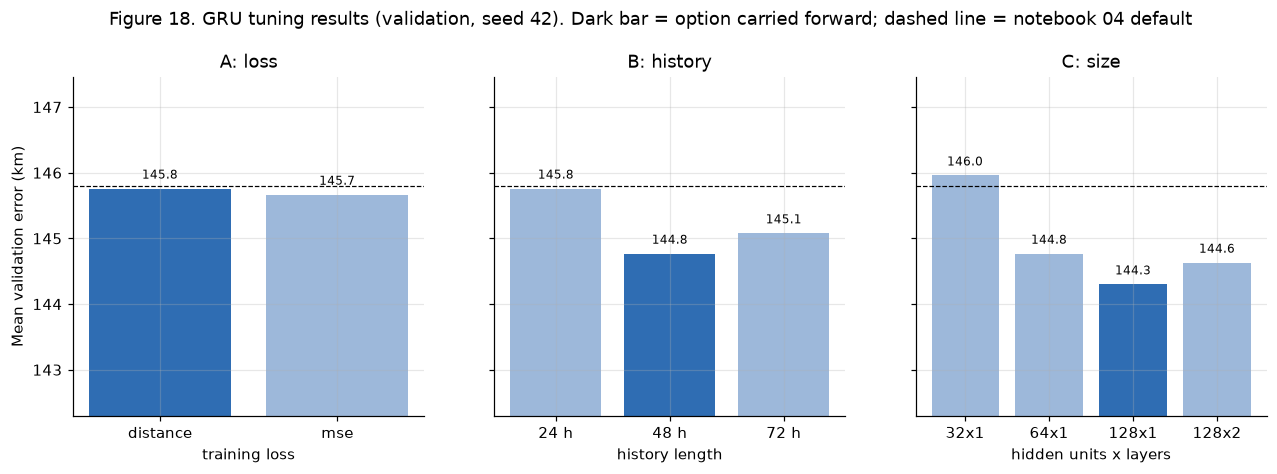

In [11]:
res = pd.DataFrame(log)
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
labels = {"A: loss": lambda r: r["loss"],
          "B: history": lambda r: r["history"],
          "C: size": lambda r: f"{r['hidden']}x{r['layers']}"}
chosen = {"A: loss": best_loss, "B: history": HISTORIES[best_steps], "C: size": f"{best_hidden}x{best_layers}"}
for ax, (exp, lab) in zip(axes, labels.items()):
    sub = res[res["experiment"] == exp]
    names = [lab(r) for _, r in sub.iterrows()]
    ax.bar(names, sub["val_mean_km"], color=["#2F6DB3" if n == chosen[exp] else "#9DB8DA" for n in names])
    for i, v in enumerate(sub["val_mean_km"]):
        ax.text(i, v + 0.15, f"{v:.1f}", ha="center", fontsize=8)
    ax.axhline(145.8, color="k", ls="--", lw=0.8)
    ax.set(title=exp, xlabel={"A: loss": "training loss", "B: history": "history length",
                              "C: size": "hidden units x layers"}[exp])
lo = res["val_mean_km"].min()
axes[0].set(ylabel="Mean validation error (km)", ylim=(lo - 2, res["val_mean_km"].max() + 1.5))
fig.suptitle("Figure 18. GRU tuning results (validation, seed 42). Dark bar = option carried forward; dashed line = notebook 04 default", y=1.03)
savefig(fig, "fig18_tuning_results.png")
plt.show()

## 6. Training the final models

With the configuration chosen, the cell below trains it properly, just as in notebook 04: three seeds each
for a GRU and an LSTM, with the three forecasts of each cell type averaged into an ensemble. Training the
LSTM with the same tuned settings also shows whether the choices carry over to the other cell type. The
models are saved as `tuned_<cell>_seed<seed>.pt`.

In [12]:
final_runs, final_disp = [], {}
for cell in ["gru", "lstm"]:
    final_disp[cell] = []
    for seed in FINAL_SEEDS:
        row, model, disp, _ = run("final", cell=cell, seed=seed, keep=True, **BEST)
        torch.save(model.state_dict(), MODEL_DIR / f"tuned_{cell}_seed{seed}.pt")
        final_disp[cell].append(disp)
        final_runs.append(row)
seeds_tab = pd.DataFrame(final_runs)[["cell", "seed", "val_mean_km", "epochs", "secs"]].round(1)
display(seeds_tab.pivot(index="seed", columns="cell", values="val_mean_km"))
seeds_tab.groupby("cell")["val_mean_km"].agg(["mean", "std"]).round(2)

cell,GRU,LSTM
seed,,
7,144.6,144.6
42,144.3,145.1
2024,144.8,145.2


,mean,std
cell,,
GRU,144.57,0.25
LSTM,144.97,0.32


So, three seeds each for the tuned configuration (48-hour history, 128 hidden units, one layer):

- **GRU:** the three runs average 144.6 km, with a spread of 144.3 to 144.8 km.
- **LSTM:** the three runs average 145.0 km, with a spread of 144.6 to 145.2 km.
- **Both** are about 1 km better than their notebook 04 counterparts.

One honest observation: the seed-to-seed spread is a little wider than in notebook 04 (about 0.5 km instead of 0.3 km). That means the 0.3 km tie margin used during the search was on the tight side, and the smallest differences in the search (such as 128 versus 64 units) are close to the noise level. The final comparison below uses all three seeds, which is more reliable than any single-seed result.

## 7. Did tuning pay off?

Now for the real test of the tuning: the tuned ensembles against everything that came before. The cell
below loads the per-forecast validation errors saved by notebooks 03 and 04, checks they line up forecast
by forecast, and builds the familiar summary table.

In [13]:
kw = dict(keep_default_na=False, na_values=[""], parse_dates=["ISO_TIME"])   # keep basin code "NA" as text
base = pd.read_csv(PROCESSED / "preds_val_baselines.csv", **kw)
rnn = pd.read_csv(PROCESSED / "preds_val_rnn.csv", **kw)
for f in (base, rnn):
    assert (f["SEG_ID"].to_numpy() == va["SEG_ID"].to_numpy()).all(), "forecasts not aligned"

err = {"Persistence": base["err_persistence_km"].to_numpy(),
       "XGBoost": base["err_xgboost_km"].to_numpy(),
       "GRU default (nb 04)": rnn["err_gru_ens_km"].to_numpy(),
       "LSTM default (nb 04)": rnn["err_lstm_ens_km"].to_numpy(),
       "GRU tuned": track_error_km(va, np.mean(final_disp["gru"], axis=0)),
       "LSTM tuned": track_error_km(va, np.mean(final_disp["lstm"], axis=0))}
na = va["BASIN"].eq("NA").to_numpy()
hi = va["LAT"].abs().ge(25).to_numpy()
summary = pd.DataFrame({m: {"mean_km": e.mean(), "median_km": np.median(e), "p90_km": np.percentile(e, 90),
                            "NA_mean_km": e[na].mean(), "beyond_25deg_km": e[hi].mean()}
                        for m, e in err.items()}).T
summary["skill_vs_persistence_%"] = 100 * (1 - summary["mean_km"] / summary.loc["Persistence", "mean_km"])
summary.round(1)

,mean_km,median_km,p90_km,NA_mean_km,beyond_25deg_km,skill_vs_persistence_%
Persistence,168.0,139.2,320.3,182.9,241.4,0.0
XGBoost,148.5,126.4,277.2,163.7,202.7,11.6
GRU default (nb 04),145.2,123.4,273.1,155.9,194.0,13.5
LSTM default (nb 04),146.0,125.3,276.3,156.6,194.6,13.0
GRU tuned,144.0,122.0,272.2,155.8,191.1,14.3
LSTM tuned,144.3,121.2,271.0,155.4,191.5,14.1


Tuning helps, though by a modest amount:

- **GRU ensemble:** goes from 145.2 to **144.0 km**, now 14.3% better than persistence.
- **LSTM ensemble:** goes from 146.0 to 144.3 km, which nearly closes the gap to the GRU.
- **Recurvature zone** (beyond 25°): both tuned networks improve further, to about 191 km, compared with 194 km before tuning and 203 km for XGBoost.
- **North Atlantic:** barely changes (about 155–156 km).

It makes sense: the extra history helps most with storms that are turning, and the Atlantic gain was already captured in notebook 04.

As before, we check the key differences with the storm-level paired bootstrap: 2,000 resamples of whole
validation storms, giving a 95% interval for each difference. A positive number means the second model is
better.

In [14]:
def paired_bootstrap(err_a, err_b, groups, n_boot=2000, seed=42):
    diff = pd.DataFrame({"g": groups, "d": err_a - err_b}).groupby("g")["d"].agg(["sum", "size"])
    s, n = diff["sum"].to_numpy(), diff["size"].to_numpy()
    idx = np.random.default_rng(seed).integers(0, len(s), size=(n_boot, len(s)))
    boots = s[idx].sum(axis=1) / n[idx].sum(axis=1)
    return s.sum() / n.sum(), *np.percentile(boots, [2.5, 97.5])

pairs = [("GRU default (nb 04)", "GRU tuned"), ("XGBoost", "GRU tuned"), ("LSTM tuned", "GRU tuned")]
pd.DataFrame([{"comparison": f"{a} minus {b}",
               **dict(zip(["mean_diff_km", "ci_low_km", "ci_high_km"], paired_bootstrap(err[a], err[b], va["SID"])))}
              for a, b in pairs]).set_index("comparison").round(1)

,mean_diff_km,ci_low_km,ci_high_km
comparison,,,
GRU default (nb 04) minus GRU tuned,1.3,0.5,2.0
XGBoost minus GRU tuned,4.6,2.9,6.3
LSTM tuned minus GRU tuned,0.3,-0.2,0.9


Taking the bootstrap results in turn:

- **Tuned versus default GRU:** the tuned GRU beats its notebook 04 version by 1.3 km (95% interval 0.5 to 2.0 km). That's small, but it stays clear of zero.
- **Tuned GRU versus XGBoost:** the lead grows to 4.6 km (2.9 to 6.3 km).
- **Tuned LSTM versus tuned GRU:** the gap is now only 0.3 km, and its interval (−0.2 to 0.9 km) includes zero. So after tuning, the two cell types are statistically tied on these seasons.

One caveat applies to all of this. The validation seasons were used to *choose* the configuration, so the tuned models' validation scores are a little optimistic, and the bootstrap can't correct for that. Only the untouched test seasons can say how much of the 1.3 km gain is real.

Finally, Figure 19 puts the whole validation story on one chart: every model from persistence to the tuned
networks, for all basins and for the North Atlantic.

saved reports/figures/fig19_tuned_vs_all.png


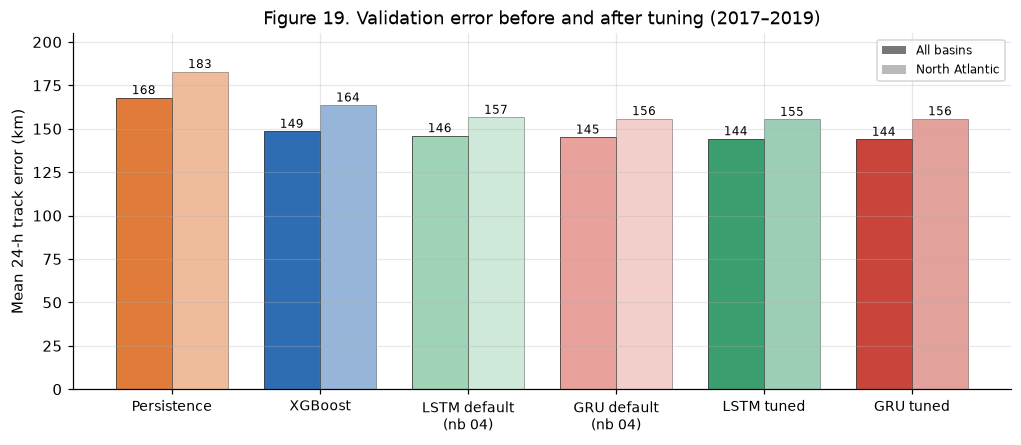

In [15]:
order = ["Persistence", "XGBoost", "LSTM default (nb 04)", "GRU default (nb 04)", "LSTM tuned", "GRU tuned"]
colors = ["#E07B39", "#2F6DB3", "#9FD3B5", "#E9A19B", "#3A9E6F", "#C9453B"]
fig, ax = plt.subplots(figsize=(11, 4.2))
x, w = np.arange(len(order)), 0.38
for k, (col, alpha) in enumerate([("mean_km", 1.0), ("NA_mean_km", 0.5)]):
    vals = summary.loc[order, col]
    ax.bar(x + (k - 0.5) * w, vals, w, color=colors, alpha=alpha, edgecolor="k", lw=0.4)
    for xi, v in zip(x + (k - 0.5) * w, vals):
        ax.text(xi, v + 2, f"{v:.0f}", ha="center", fontsize=8)
ax.set_xticks(x, [o.replace(" (nb 04)", "\n(nb 04)") for o in order], fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor="#777", label="All basins"), Patch(facecolor="#777", alpha=0.5, label="North Atlantic")], fontsize=8)
ax.set(ylabel="Mean 24-h track error (km)", ylim=(0, summary.loc[order, "NA_mean_km"].max() * 1.12),
       title="Figure 19. Validation error before and after tuning (2017–2019)")
savefig(fig, "fig19_tuned_vs_all.png")
plt.show()

## 8. Save the tuned models' forecasts and settings

Last, we save what the final evaluation needs: the tuned ensembles' validation errors, and a config file
recording the chosen settings, seeds and scaling statistics. The final notebook will use that config to
rebuild exactly these networks and run them on the test seasons.

In [16]:
out = va[["SID", "SEG_ID", "BASIN", "SEASON", "ISO_TIME"]].copy()
out["err_gru_tuned_km"], out["err_lstm_tuned_km"] = err["GRU tuned"], err["LSTM tuned"]
out.to_csv(PROCESSED / "preds_val_tuned.csv", index=False)

_, _, seq_stats = TENSORS[BEST["n_steps"]]
config = {**BEST, "dropout": 0.1, "seeds": FINAL_SEEDS, "static_features": STATIC, "step_features": STEP_FEATURES,
          **seq_stats, "st_mu": st_mu.tolist(), "st_sd": st_sd.tolist(), "y_scale": y_scale.tolist()}
(MODEL_DIR / "tuned_config.json").write_text(json.dumps(config, indent=2))
pd.DataFrame(log).to_csv(PROCESSED / "tuning_log.csv", index=False)
print("saved data/processed/preds_val_tuned.csv, data/processed/tuning_log.csv, models/tuned_config.json,",
      ", ".join(sorted(p.name for p in MODEL_DIR.glob("tuned_*.pt"))))

saved data/processed/preds_val_tuned.csv, data/processed/tuning_log.csv, models/tuned_config.json, tuned_gru_seed2024.pt, tuned_gru_seed42.pt, tuned_gru_seed7.pt, tuned_lstm_seed2024.pt, tuned_lstm_seed42.pt, tuned_lstm_seed7.pt


## Summary

So, here's what tuning taught us, all on the validation seasons (2017–2019):

| Question | Answer | Effect |
|---|---|---|
| Distance loss or squared error? | No difference (145.8 vs 145.7 km) | The gain over XGBoost comes from the sequence model, not the loss |
| How much history? | **48 hours** (7 steps) | About 1 km better than 24 h; 72 h adds nothing |
| How big? | **128 hidden units, 1 layer** | Better than 32 or 64; a second layer adds nothing |

And here's the resulting leaderboard:

| Model | Mean error | North Atlantic | Beyond 25° | Skill vs persistence |
|---|---|---|---|---|
| Persistence | 168.0 km | 183 km | 241 km | 0% |
| XGBoost | 148.5 km | 164 km | 203 km | 11.6% |
| GRU default (nb 04) | 145.2 km | 156 km | 194 km | 13.5% |
| LSTM tuned | 144.3 km | 155 km | 192 km | 14.1% |
| **GRU tuned** | **144.0 km** | **156 km** | **191 km** | **14.3%** |

A few honest limits are worth stating:

- **Coordinate search, not a full grid.** We changed one setting at a time, so a combination that only helps when two settings change together could have been missed. Learning rate, dropout and batch size were left at their defaults.
- **Small gains near the noise level.** The improvements from tuning are about 1 km, close to the 0.5 km spread between seeds, which is why the final models are 3-seed ensembles.
- **Slightly optimistic validation scores.** The validation seasons picked the configuration, so the tuned models' scores there are a little flattering.

And that last point is exactly why the next notebook matters. It takes the tuned GRU and LSTM, plus every baseline, and scores them once, on the **test seasons (2020–2024)** that no model or decision has touched. That gives the honest final numbers, and the fair comparison with the NHC's 63 km.

**In production**, the tuned GRU would need the storm's last 48 hours of fixes rather than 24. For a storm younger than two days, the `valid` flag lets it run on whatever history exists, which is exactly how it was trained.

## References

Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine
Learning Research, 13*, 281–305.

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H., & Bengio, Y. (2014).
Learning phrase representations using RNN encoder–decoder for statistical machine translation. In
*Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing* (pp. 1724–1734).
https://doi.org/10.3115/v1/D14-1179

Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8), 1735–1780.
https://doi.org/10.1162/neco.1997.9.8.1735

*AI-tool disclosure: Claude (Anthropic) helped draft this notebook's code and explanations. The author
reviewed each step, ran the notebook, and checked the outputs.*